# gliner-base fine-tuning on the 17-entity news ner dataset
supervised baseline for the paper table (no zero-shot here).

**kaggle setup before run all**
- accelerator: gpu t4 x2 or p100 (code pins to 1 gpu)
- internet: on
- add-ons > secrets: add `HF_TOKEN` (dataset repo is private)

**pipeline:** load data -> bio to span format -> fine-tune (time capped) -> tune threshold on val -> test with seqeval + per-tag p/r/f1 -> full error analysis (type confusion, boundary, miss, spurious) -> plots + csvs

In [1]:
!pip install -q gliner seqeval || pip install -q --no-build-isolation seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, time, json, math, random, re, shutil, glob, warnings, collections
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          # gliner + dataparallel = pain, so 1 gpu only
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ---------------- config ----------------
SEED        = 42
DATASET     = "Souvikbasur/17entity-news-ner-dataset"
BASE_MODEL  = "urchade/gliner_base"
EPOCHS      = 3
BATCH       = 8
LR_ENCODER  = 1e-5
LR_OTHERS   = 3e-5
TRAIN_TIME_LIMIT_MIN = 65          # hard stop for training so whole notebook stays < ~1.5h
THRESHOLDS  = [0.3, 0.4, 0.5, 0.6, 0.7]   # tuned on VAL only
OUT         = "/kaggle/working"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("cuda:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - turn on accelerator!")

cuda: True Tesla T4


In [3]:
# ---------------- helpers (pure python, no model) ----------------
def bio_to_spans(tags):
    spans, start, lab = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t.startswith("I-") and start is not None and t[2:] == lab:
            continue
        if start is not None:
            spans.append((start, i - 1, lab)); start, lab = None, None   # end INCLUSIVE
        if t.startswith("B-") or t.startswith("I-"):                    # stray I- also opens a span
            start, lab = i, t[2:]
    return spans

def spans_to_bio(n, spans):
    tags = ["O"] * n
    for s, e, l in spans:
        tags[s] = "B-" + l
        for k in range(s + 1, e + 1): tags[k] = "I-" + l
    return tags

def overlap(a, b): return not (a[1] < b[0] or b[1] < a[0])
def ov_len(a, b):  return min(a[1], b[1]) - max(a[0], b[0]) + 1

def score(rows, preds, labels):
    # exact-span entity-level p/r/f1 (same definition as seqeval default)
    cnt = {l: [0, 0, 0] for l in labels}   # tp, fp, fn
    for r, p in zip(rows, preds):
        G, P = set(r["gold"]), set(p)
        for s, e, l in G & P: cnt[l][0] += 1
        for s, e, l in P - G: cnt[l][1] += 1
        for s, e, l in G - P: cnt[l][2] += 1
    recs = []
    for l in labels:
        tp, fp, fn = cnt[l]
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn) if tp + fn else 0.0
        f  = 2 * pr * rc / (pr + rc) if pr + rc else 0.0
        recs.append(dict(tag=l, precision=pr, recall=rc, f1=f, support=tp + fn, tp=tp, fp=fp, fn=fn))
    df = pd.DataFrame(recs)
    TP, FP, FN = df.tp.sum(), df.fp.sum(), df.fn.sum()
    mp = TP / (TP + FP) if TP + FP else 0.0
    mr = TP / (TP + FN) if TP + FN else 0.0
    mf = 2 * mp * mr / (mp + mr) if mp + mr else 0.0
    d = df[df.support > 0]; sup = d.support.sum()
    summ = dict(micro_p=mp, micro_r=mr, micro_f1=mf,
                macro_p=d.precision.mean(), macro_r=d.recall.mean(), macro_f1=d.f1.mean(),
                weighted_p=(d.precision * d.support).sum() / sup,
                weighted_r=(d.recall * d.support).sum() / sup,
                weighted_f1=(d.f1 * d.support).sum() / sup)
    return df, summ

def analyse(rows, preds):
    # error taxonomy per gold entity: exact / type_confusion / boundary_error / true_miss, plus true_spurious preds
    errs, cm, n_exact = [], collections.Counter(), 0
    for sid, (r, p) in enumerate(zip(rows, preds)):
        G, P = set(r["gold"]), set(p)
        exact = G & P
        n_exact += len(exact)
        for g in exact: cm[(g[2], g[2])] += 1
        toks = r["tokens"]; sent = " ".join(toks)
        txt = lambda sp: " ".join(toks[sp[0]:sp[1] + 1]) if sp else None
        used = set()
        for g in sorted(G - exact):
            ov = [q for q in (P - exact) if overlap(g, q)]
            if not ov:
                kind, bk, q = "true_miss", None, None
                cm[(g[2], "O")] += 1
            else:
                used.update(ov)
                same = [q for q in ov if q[2] == g[2]]
                q = max(same if same else ov, key=lambda x: ov_len(g, x))
                if q[2] == g[2]:
                    kind = "boundary_error"
                    if len(ov) >= 2:                          bk = "fragmented"
                    elif q[0] <= g[0] and q[1] >= g[1]:       bk = "over_span"
                    elif g[0] <= q[0] and g[1] >= q[1]:       bk = "under_span"
                    else:                                     bk = "shifted"
                else:
                    kind = "type_confusion"
                    bk = "same_span" if (q[0], q[1]) == (g[0], g[1]) else "diff_span"
                cm[(g[2], q[2])] += 1
            errs.append(dict(sent_id=sid, error_kind=kind, boundary_kind=bk,
                             gold_label=g[2], pred_label=q[2] if q else None,
                             gold_text=txt(g), pred_text=txt(q), gold_len=g[1] - g[0] + 1, sentence=sent))
        for q in (P - exact - used):
            errs.append(dict(sent_id=sid, error_kind="true_spurious", boundary_kind=None,
                             gold_label=None, pred_label=q[2], gold_text=None, pred_text=txt(q),
                             gold_len=None, sentence=sent))
            cm[("O", q[2])] += 1
    return pd.DataFrame(errs), cm, n_exact
print("helpers ok")

helpers ok


## 1. data

In [7]:
from huggingface_hub import login, hf_hub_download
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(HF_TOKEN)

# raw label studio json = the SAME file your k-fold / modernbert / luke notebooks used
DATA_PATH = hf_hub_download(repo_id=DATASET, filename="17entity_news_ner_dataset.json",
                            repo_type="dataset", token=HF_TOKEN)

K_FOLDS, FOLD_IDX, VAL_FRACTION_WITHIN_TRAIN = 5, 2, 0.10
ENTITY_TAGS = ["PER", "ORG", "LOC", "FAC", "DATE", "TIME", "EVT", "PROD", "MONEY", "PCT", "LAW", "NORP", "LANG", "WOA", "QTY", "ORD", "CARD"]

# ---------- copied from roberta_crf_vs_modernbert_fold2_comparison.ipynb (unchanged) ----------
def parse_label_studio(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    tasks, skipped, seen_texts = [], 0, set()
    for item in raw:
        text = item.get("data", {}).get("text", "").strip()
        if not text or text in seen_texts:
            skipped += 1
            continue
        seen_texts.add(text)
        entities = []
        annotations = item.get("annotations", [])
        if annotations:
            for result in annotations[0].get("result", []):
                val = result.get("value", {})
                start, end, labels = val.get("start"), val.get("end"), val.get("labels", [])
                if start is None or end is None or not labels:
                    continue
                if labels[0] in ENTITY_TAGS:
                    entities.append((start, end, labels[0]))
        tasks.append({"text": text, "entities": entities})
    print(f"[Parse] Loaded {len(tasks)} tasks, skipped {skipped}.")
    return tasks

def build_folds(tasks, k=K_FOLDS, seed=SEED):
    shuffled = tasks[:]
    random.Random(seed).shuffle(shuffled)
    n = len(shuffled); fold_size = n // k
    folds, start = [], 0
    for i in range(k):
        end = start + fold_size if i < k - 1 else n
        folds.append(shuffled[start:end]); start = end
    sizes = [len(f) for f in folds]
    print(f"[Fold build] {k} folds from {n} sentences, sizes: {sizes}")
    assert sum(sizes) == n
    return folds

def train_val_split_within_pool(pool, val_fraction=VAL_FRACTION_WITHIN_TRAIN, seed=SEED):
    p = pool[:]
    random.Random(seed).shuffle(p)
    n_val = int(len(p) * val_fraction)
    return p[n_val:], p[:n_val]
# ----------------------------------------------------------------------------------------------

tasks = parse_label_studio(DATA_PATH)
folds = build_folds(tasks, k=K_FOLDS, seed=SEED)
test_tasks  = folds[FOLD_IDX]
train_pool  = [t for i, f in enumerate(folds) if i != FOLD_IDX for t in f]
train_tasks, val_tasks = train_val_split_within_pool(train_pool)

tr_t, va_t, te_t = ({t["text"] for t in x} for x in (train_tasks, val_tasks, test_tasks))
assert tr_t.isdisjoint(va_t) and tr_t.isdisjoint(te_t) and va_t.isdisjoint(te_t), "split overlap"
print(f"Fold {FOLD_IDX} | train {len(train_tasks)} | val {len(val_tasks)} | test {len(test_tasks)}")
if len(test_tasks) != 4808:
    print("WARNING: test size is not 4808 -> split differs from modernbert/luke run, do not compare!")

# ---- char spans -> word tokens (same splitter gliner uses) -> token spans ----
TOK_RE = re.compile(r"\w+(?:[-_]\w+)*|\S")
ALIGN = collections.Counter()

def task_to_row(task):
    text = task["text"]
    toks = [(m.group(), m.start(), m.end()) for m in TOK_RE.finditer(text)]
    spans = []
    for cs, ce, lab in task["entities"]:
        seg = text[cs:ce]
        ls, re_ = cs + (len(seg) - len(seg.lstrip())), ce - (len(seg) - len(seg.rstrip()))
        s = next((i for i, t in enumerate(toks) if t[2] > ls), None)
        e = next((i for i in range(len(toks) - 1, -1, -1) if toks[i][1] < re_), None)
        if s is None or e is None or e < s: continue
        ALIGN["gold_spans"] += 1
        if toks[s][1] != ls or toks[e][2] != re_: ALIGN["not_on_word_boundary"] += 1
        spans.append((s, e, lab))
    spans.sort(key=lambda x: -(x[1] - x[0]))            # drop overlaps, longest first
    keep = []
    for sp in spans:
        if not any(overlap(sp, k) for k in keep): keep.append(sp)
    keep.sort()
    tokens = [t[0] for t in toks]
    return dict(tokens=tokens, tags=spans_to_bio(len(tokens), keep), gold=keep, text=text)

train_raw = [task_to_row(t) for t in train_tasks]
val_raw   = [task_to_row(t) for t in val_tasks]
test_raw  = [task_to_row(t) for t in test_tasks]
print("alignment:", dict(ALIGN), "(not_on_word_boundary should be tiny)")

LABELS = list(ENTITY_TAGS)                               # same 17 tags, same order as your other notebooks
NL = {"PER":"person","ORG":"organization","LOC":"location","NORP":"nationality or religious or political group",
      "DATE":"date","TIME":"time","MONEY":"money","PCT":"percentage","CARD":"cardinal number","ORD":"ordinal number",
      "QTY":"quantity","EVT":"event","LAW":"law","FAC":"facility","PROD":"product","LANG":"language","WOA":"work of art"}
to_gl  = lambda l: NL.get(l, l.lower())
GL_LABELS = [to_gl(l) for l in LABELS]
GL2TAG = {to_gl(l): l for l in LABELS}

def to_gliner(rows):
    return [{"tokenized_text": r["tokens"], "ner": [[s, e, to_gl(l)] for s, e, l in r["gold"]]} for r in rows]
train_gl, val_gl = to_gliner(train_raw), to_gliner(val_raw)

print(len(LABELS), "labels")
print(pd.Series([l for r in train_raw for _, _, l in r["gold"]]).value_counts().to_string())
print("empty-entity train sentences:", sum(1 for r in train_raw if not r["gold"]))
print(train_raw[0]["tokens"][:15], train_raw[0]["gold"][:3])

[Parse] Loaded 24044 tasks, skipped 822.
[Fold build] 5 folds from 24044 sentences, sizes: [4808, 4808, 4808, 4808, 4812]
Fold 2 | train 17313 | val 1923 | test 4808
alignment: {'gold_spans': 70185, 'not_on_word_boundary': 26} (not_on_word_boundary should be tiny)
17 labels
ORG      10097
LOC       9628
PER       8176
DATE      6678
NORP      3629
CARD      3365
MONEY     1641
PCT       1103
PROD      1019
WOA       1016
ORD        856
QTY        834
EVT        706
TIME       602
LAW        521
FAC        446
LANG       146
empty-entity train sentences: 1147
['Parliament', 'Vs', 'the', 'Prime', 'Minister', 'If', 'the', 'judiciary', 'reflected', 'institutional', 'discomfort', ',', 'Parliament', 'reflected', 'outright'] [(12, 12, 'ORG')]


## 2. fine-tune (time capped)

In [8]:
from transformers import Trainer, TrainerCallback
from gliner import GLiNER

class TimeLimit(TrainerCallback):
    def on_step_end(self, args, state, control, **kw):
        if (time.time() - T0) / 60 > TRAIN_TIME_LIMIT_MIN:
            control.should_training_stop = True
            print(f"[time limit] stopping at step {state.global_step}")
        return control

if not hasattr(Trainer, "_tl_patched"):          # inject callback into whatever trainer gliner builds
    _orig_init = Trainer.__init__
    def _patched(self, *a, **k):
        _orig_init(self, *a, **k); self.add_callback(TimeLimit())
    Trainer.__init__ = _patched; Trainer._tl_patched = True

steps_per_epoch = math.ceil(len(train_gl) / BATCH)
max_steps = steps_per_epoch * EPOCHS
print(f"steps/epoch {steps_per_epoch} | max_steps {max_steps}")

model = GLiNER.from_pretrained(BASE_MODEL)
model.to("cuda")

base = dict(output_dir=f"{OUT}/gliner_ft", learning_rate=LR_ENCODER, others_lr=LR_OTHERS,
            weight_decay=0.01, others_weight_decay=0.01, lr_scheduler_type="linear", warmup_ratio=0.1,
            per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH * 2,
            max_steps=max_steps, save_steps=steps_per_epoch, save_total_limit=2, logging_steps=100,
            bf16=False, fp16=True, dataloader_num_workers=2, report_to="none")
ev = dict(eval_steps=steps_per_epoch, save_strategy="steps", load_best_model_at_end=True,
          metric_for_best_model="eval_loss", greater_is_better=False)
variants = [dict(**ev, eval_strategy="steps"),          # new transformers
            dict(**ev, evaluation_strategy="steps"),    # old transformers
            dict()]                                      # last resort: no eval, final weights
T0 = time.time()
for i, v in enumerate(variants):
    try:
        model.train_model(train_gl, val_gl, **base, **v)
        break
    except (TypeError, ValueError) as e:
        print(f"variant {i} failed: {e}")
        if i == len(variants) - 1: raise
print(f"training done in {(time.time() - T0) / 60:.1f} min")
model.eval(); torch.cuda.empty_cache()

steps/epoch 2165 | max_steps 6495


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1, 'pad_token_id': 0}.


Step,Training Loss,Validation Loss
2165,16.626099,29.603926
4330,12.081395,28.118057
6495,11.893193,27.091236


training done in 19.2 min


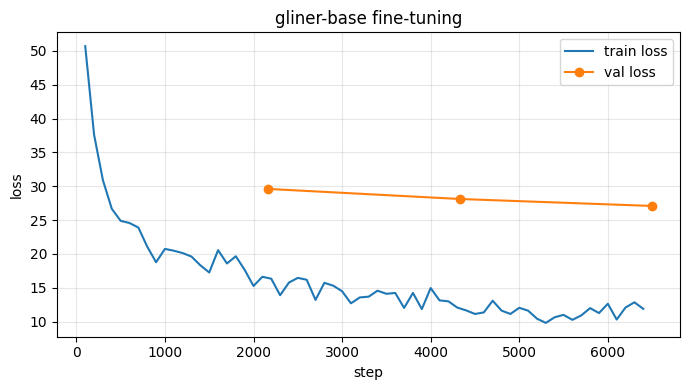

saved: /kaggle/working/gliner_news_ft_final


In [9]:
# loss curves + save final model, then clear heavy checkpoints
sts = sorted(glob.glob(f"{OUT}/gliner_ft/**/trainer_state.json", recursive=True), key=os.path.getmtime)
if sts:
    hist = json.load(open(sts[-1]))["log_history"]
    tl = [(h["step"], h["loss"]) for h in hist if "loss" in h]
    el = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    plt.figure(figsize=(7, 4))
    if tl: plt.plot(*zip(*tl), label="train loss")
    if el: plt.plot(*zip(*el), "o-", label="val loss")
    plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.title("gliner-base fine-tuning")
    plt.tight_layout(); plt.savefig(f"{OUT}/loss_curve_gliner.png", dpi=200); plt.show()
    shutil.copy(sts[-1], f"{OUT}/trainer_state_gliner.json")
model.save_pretrained(f"{OUT}/gliner_news_ft_final")
shutil.rmtree(f"{OUT}/gliner_ft", ignore_errors=True)
print("saved:", f"{OUT}/gliner_news_ft_final")

## 3. inference on token-level data

In [10]:
# gliner takes raw text -> we join tokens with single spaces, predict, map char offsets back to token idx
def tokens_to_text(tokens):
    offs, pos = [], 0
    for t in tokens:
        offs.append((pos, pos + len(t))); pos += len(t) + 1
    return " ".join(tokens), offs

MISALIGN = collections.Counter()
def char_to_tok(offs, cs, ce):
    s = next((i for i, (a, b) in enumerate(offs) if b > cs), None)
    e = next((i for i in range(len(offs) - 1, -1, -1) if offs[i][0] < ce), None)
    if s is None or e is None or e < s: return None
    MISALIGN["total"] += 1
    if cs != offs[s][0] or ce != offs[e][1]: MISALIGN["mid_token"] += 1   # gliner word splitter cut inside a dataset token
    return s, e

@torch.inference_mode()
def predict_split(rows, threshold, bs=32):
    texts, offsets = zip(*[tokens_to_text(r["tokens"]) for r in rows])
    preds = []
    for i in tqdm(range(0, len(texts), bs), leave=False):
        chunk = list(texts[i:i + bs])
        try:
            out = model.batch_predict_entities(chunk, GL_LABELS, flat_ner=True, threshold=threshold)
        except AttributeError:
            out = [model.predict_entities(t, GL_LABELS, flat_ner=True, threshold=threshold) for t in chunk]
        for j, ents in enumerate(out):
            offs, sp = offsets[i + j], set()
            for en in ents:
                m = char_to_tok(offs, en["start"], en["end"])
                if m: sp.add((m[0], m[1], GL2TAG[en["label"]]))
            preds.append(sorted(sp))
    return preds
print("predict fn ready")

predict fn ready


## 4. tune threshold on validation only

In [11]:
rows = []
for th in THRESHOLDS:
    t = time.time()
    pv = predict_split(val_raw, th)
    _, sm = score(val_raw, pv, LABELS)
    rows.append(dict(threshold=th, val_p=sm["micro_p"], val_r=sm["micro_r"], val_f1=sm["micro_f1"], sec=round(time.time() - t)))
    print(rows[-1])
th_df = pd.DataFrame(rows); BEST_TH = float(th_df.sort_values("val_f1").iloc[-1]["threshold"])
th_df.to_csv(f"{OUT}/threshold_tuning_val.csv", index=False)
print("\nbest threshold (val):", BEST_TH)

  0%|          | 0/61 [00:00<?, ?it/s]

{'threshold': 0.3, 'val_p': np.float64(0.8446519524617997), 'val_r': np.float64(0.8923766816143498), 'val_f1': np.float64(0.867858700392499), 'sec': 20}


  0%|          | 0/61 [00:00<?, ?it/s]

{'threshold': 0.4, 'val_p': np.float64(0.8541953232462174), 'val_r': np.float64(0.8911210762331838), 'val_f1': np.float64(0.8722675796681592), 'sec': 20}


  0%|          | 0/61 [00:00<?, ?it/s]

{'threshold': 0.5, 'val_p': np.float64(0.8636205092431113), 'val_r': np.float64(0.8882511210762332), 'val_f1': np.float64(0.8757626669024671), 'sec': 20}


  0%|          | 0/61 [00:00<?, ?it/s]

{'threshold': 0.6, 'val_p': np.float64(0.8742461865909897), 'val_r': np.float64(0.8841255605381166), 'val_f1': np.float64(0.8791581200392401), 'sec': 19}


  0%|          | 0/61 [00:00<?, ?it/s]

{'threshold': 0.7, 'val_p': np.float64(0.8871348212665577), 'val_r': np.float64(0.8769506726457399), 'val_f1': np.float64(0.8820133501713873), 'sec': 19}

best threshold (val): 0.7


## 5. test evaluation (precision / recall / f1 + seqeval)

In [12]:
MISALIGN.clear()
test_preds = predict_split(test_raw, BEST_TH)
print("char->token alignment:", dict(MISALIGN), "(mid_token should be ~0)")

tag_df, S = score(test_raw, test_preds, LABELS)

from seqeval.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score
y_true = [r["tags"] for r in test_raw]
y_pred = [spans_to_bio(len(r["tokens"]), p) for r, p in zip(test_raw, test_preds)]

print("=== seqeval (default, conlleval-style) ===")
print(classification_report(y_true, y_pred, digits=4))
try:
    from seqeval.scheme import IOB2
    print("=== seqeval strict IOB2 ===")
    print(classification_report(y_true, y_pred, mode="strict", scheme=IOB2, digits=4))
except Exception as e:
    print("strict mode skipped:", e)

sq = dict(p=precision_score(y_true, y_pred), r=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred), tok_acc=accuracy_score(y_true, y_pred))
print("seqeval micro:", {k: round(v, 4) for k, v in sq.items()})
print("own micro    :", {k: round(v, 4) for k, v in S.items() if k.startswith("micro")})
assert abs(sq["f1"] - S["micro_f1"]) < 1e-3, "own scorer and seqeval disagree - check alignment"

print("\n=== per-tag (test) ===")
show = tag_df.sort_values("f1")[["tag", "precision", "recall", "f1", "support", "tp", "fp", "fn"]]
print(show.round(4).to_string(index=False))
print("\nmicro  P/R/F1: %.4f / %.4f / %.4f" % (S["micro_p"], S["micro_r"], S["micro_f1"]))
print("macro  P/R/F1: %.4f / %.4f / %.4f" % (S["macro_p"], S["macro_r"], S["macro_f1"]))
print("weight P/R/F1: %.4f / %.4f / %.4f" % (S["weighted_p"], S["weighted_r"], S["weighted_f1"]))
print("token acc    : %.4f" % sq["tok_acc"])
tag_df.to_csv(f"{OUT}/per_tag_metrics_gliner.csv", index=False)

  0%|          | 0/151 [00:00<?, ?it/s]

char->token alignment: {'total': 13652} (mid_token should be ~0)
=== seqeval (default, conlleval-style) ===
              precision    recall  f1-score   support

        CARD     0.8486    0.8780    0.8631       926
        DATE     0.8779    0.8844    0.8811      1764
         EVT     0.7277    0.7240    0.7258       192
         FAC     0.4834    0.6887    0.5681       106
        LANG     0.7556    0.8293    0.7907        41
         LAW     0.7519    0.7042    0.7273       142
         LOC     0.9380    0.9313    0.9346      2518
       MONEY     0.8981    0.8961    0.8971       433
        NORP     0.9143    0.9240    0.9191      1039
         ORD     0.8082    0.9833    0.8872       240
         ORG     0.8913    0.8121    0.8499      2858
         PCT     0.9193    0.9273    0.9233       344
         PER     0.9399    0.9339    0.9369      2329
        PROD     0.7331    0.7572    0.7449       243
         QTY     0.8436    0.7177    0.7756       248
        TIME     0.7674    

## 6. full error analysis
taxonomy per gold entity: `exact`, `type_confusion` (wrong label), `boundary_error` (right label, wrong span: over_span / under_span / shifted / fragmented), `true_miss` (nothing predicted there); plus `true_spurious` (prediction overlapping no gold entity).

In [13]:
err_df, cm_cnt, n_exact = analyse(test_raw, test_preds)
n_gold = sum(len(r["gold"]) for r in test_raw); n_pred = sum(len(p) for p in test_preds)
gold_errs = err_df[err_df.error_kind != "true_spurious"]
assert n_exact + len(gold_errs) == n_gold, "accounting mismatch"
print(f"gold {n_gold} | pred {n_pred} | exact {n_exact} ({n_exact / n_gold:.1%}) | wrong gold {len(gold_errs)} | spurious {(err_df.error_kind == 'true_spurious').sum()}")

print("\n-- error kinds --")
print(err_df.error_kind.value_counts().to_string())
print("\n-- boundary kinds --")
print(err_df[err_df.error_kind == "boundary_error"].boundary_kind.value_counts().to_string())

kind_by_tag = (gold_errs.groupby(["gold_label", "error_kind"]).size().unstack(fill_value=0)
               .reindex(LABELS, fill_value=0))
for k in ["boundary_error", "type_confusion", "true_miss"]:
    if k not in kind_by_tag: kind_by_tag[k] = 0
kind_by_tag["spurious_pred"] = err_df[err_df.error_kind == "true_spurious"].pred_label.value_counts().reindex(LABELS, fill_value=0)
kind_by_tag["support"] = tag_df.set_index("tag").support
print("\n-- errors per tag --")
print(kind_by_tag.sort_values("support", ascending=False).to_string())

print("\n-- top type confusions (gold -> pred) --")
tc = err_df[err_df.error_kind == "type_confusion"].groupby(["gold_label", "pred_label"]).size().sort_values(ascending=False)
print(tc.head(15).to_string())

print("\n-- boundary errors by tag & kind --")
print(err_df[err_df.error_kind == "boundary_error"].groupby(["gold_label", "boundary_kind"]).size().unstack(fill_value=0).to_string())

# recall by gold span length
tot = collections.Counter(min(e - s + 1, 5) for r in test_raw for s, e, _ in r["gold"])
bad = collections.Counter(min(int(x), 5) for x in gold_errs.gold_len)
print("\n-- exact-match recall by gold span length (5 = 5+) --")
for L in sorted(tot): print(f"len {L}: {1 - bad[L] / tot[L]:.3f}  (n={tot[L]})")

err_df.to_csv(f"{OUT}/entity_error_log_gliner.csv", index=False)
kind_by_tag.to_csv(f"{OUT}/error_kinds_by_tag_gliner.csv")
cm = pd.DataFrame(0, index=LABELS + ["O"], columns=LABELS + ["O"])
for (g, p), v in cm_cnt.items(): cm.loc[g, p] = v
cm.to_csv(f"{OUT}/confusion_matrix_gliner.csv")

gold 13869 | pred 13652 | exact 12119 (87.4%) | wrong gold 1750 | spurious 430

-- error kinds --
error_kind
true_miss         655
type_confusion    562
boundary_error    533
true_spurious     430

-- boundary kinds --
boundary_kind
over_span     272
under_span    219
fragmented     39
shifted         3

-- errors per tag --
error_kind  boundary_error  true_miss  type_confusion  spurious_pred  support
gold_label                                                                   
ORG                    130        198             209             82     2858
LOC                     50         68              55             13     2518
PER                     62         42              50             21     2329
DATE                    94         83              27             92     1764
NORP                     4         48              27             47     1039
CARD                    37         38              38             63      926
MONEY                   31         11            

## 7. plots

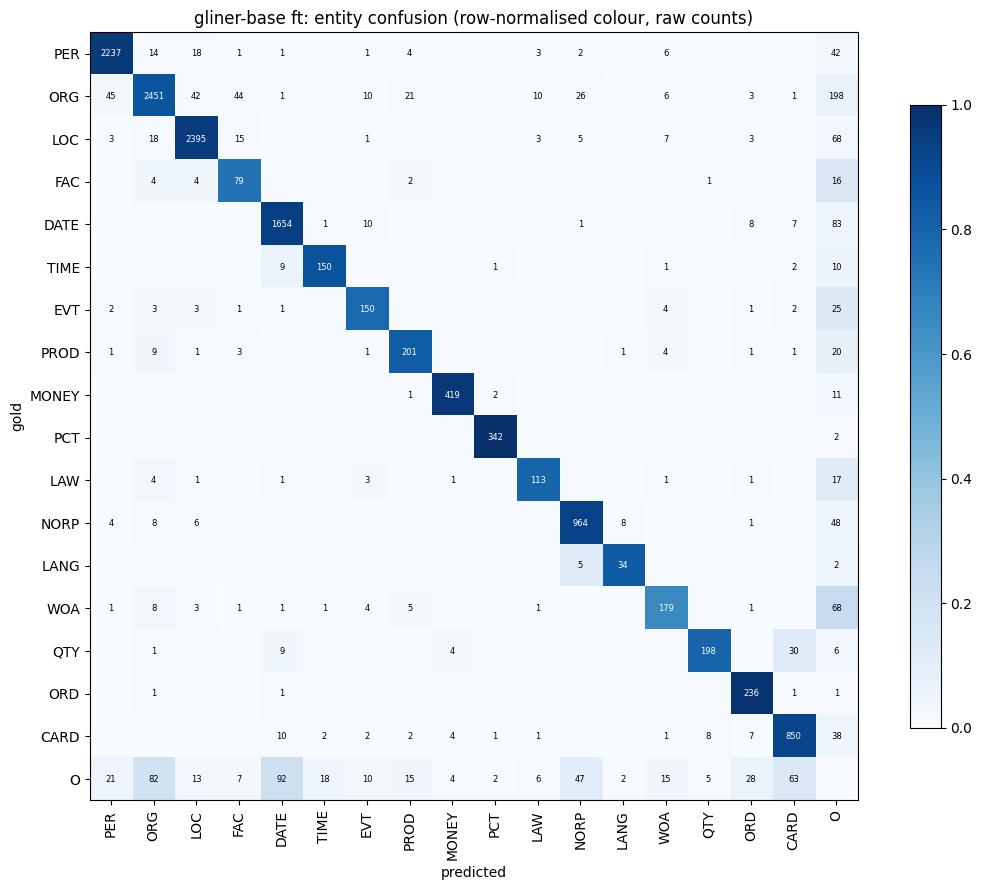

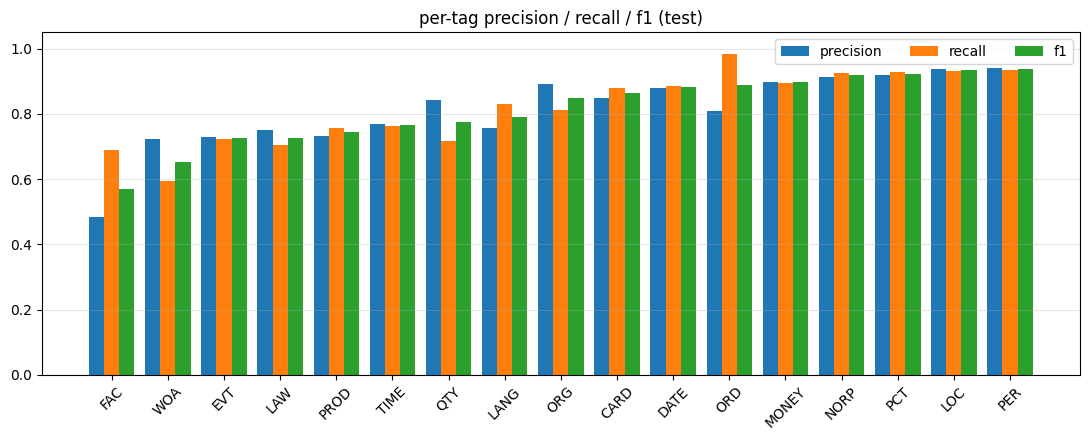

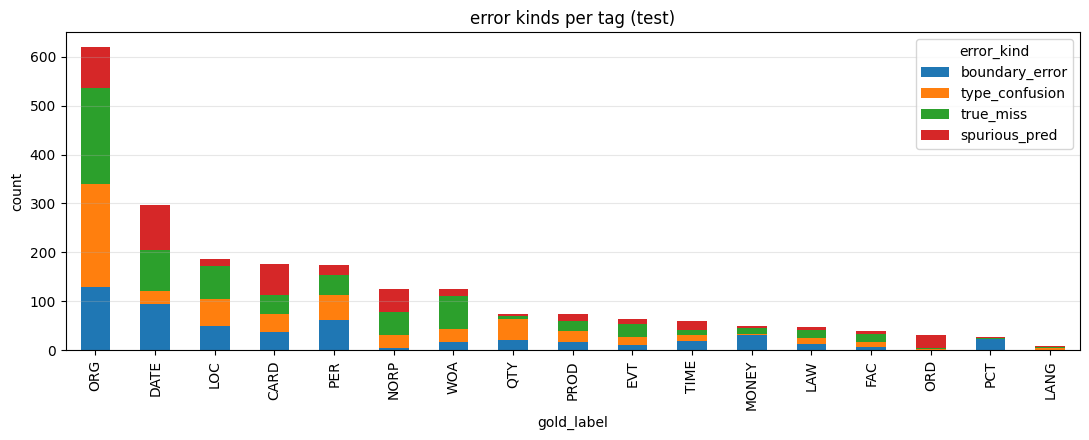

In [14]:
# confusion matrix (boundary-tolerant: rows gold, cols pred, O = miss / spurious)
norm = cm.div(cm.sum(1).replace(0, 1), axis=0)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cm.columns))); ax.set_xticklabels(cm.columns, rotation=90)
ax.set_yticks(range(len(cm.index)));   ax.set_yticklabels(cm.index)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        if v: ax.text(j, i, v, ha="center", va="center", fontsize=6, color="white" if norm.values[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title("gliner-base ft: entity confusion (row-normalised colour, raw counts)")
plt.colorbar(im, fraction=.03); plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix_gliner.png", dpi=200); plt.show()

# per-tag p/r/f1
d = tag_df[tag_df.support > 0].sort_values("f1")
x = np.arange(len(d)); w = .27
plt.figure(figsize=(11, 4.5))
plt.bar(x - w, d.precision, w, label="precision"); plt.bar(x, d.recall, w, label="recall"); plt.bar(x + w, d.f1, w, label="f1")
plt.xticks(x, d.tag, rotation=45); plt.ylim(0, 1.05); plt.legend(ncol=3); plt.grid(axis="y", alpha=.3)
plt.title("per-tag precision / recall / f1 (test)"); plt.tight_layout(); plt.savefig(f"{OUT}/per_tag_prf_gliner.png", dpi=200); plt.show()

# error kinds per tag
cols_ = [c for c in ["boundary_error", "type_confusion", "true_miss", "spurious_pred"] if c in kind_by_tag]
kb = kind_by_tag[cols_].loc[kind_by_tag[cols_].sum(1).sort_values(ascending=False).index]
kb.plot(kind="bar", stacked=True, figsize=(11, 4.5)); plt.ylabel("count"); plt.title("error kinds per tag (test)")
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/error_kinds_by_tag_gliner.png", dpi=200); plt.show()

## 8. example errors

In [16]:
def show(df, n=4, seed=SEED):
    for _, r in df.sample(min(n, len(df)), random_state=seed).iterrows():
        print(f"[{r.error_kind}/{r.boundary_kind}] gold={r.gold_label}:'{r.gold_text}'  pred={r.pred_label}:'{r.pred_text}'")
        print("   ", r.sentence[:220])

for kind in ["boundary_error", "type_confusion", "true_miss", "true_spurious"]:
    print(f"\n######## {kind} ########")
    show(err_df[err_df.error_kind == kind], n=5)

print("\n######## 4 weakest tags (3 errors each) ########")
for t in tag_df[tag_df.support > 0].sort_values("f1").tag.head(4):
    print(f"\n--- {t} ---")
    show(err_df[(err_df.gold_label == t) | ((err_df.error_kind == "true_spurious") & (err_df.pred_label == t))], n=3)


######## boundary_error ########
[boundary_error/under_span] gold=WOA:'` ` The Thief and the Dogs ' ''  pred=WOA:'The Thief and the Dogs'
    ` ` The Thief and the Dogs ' ' is a pioneering work , the first stream - of - consciousness novel in Arabic , but it is likely to disappoint Western readers .
[boundary_error/shifted] gold=EVT:'The Global Trade and Logistics Forum'  pred=EVT:'Global Trade and Logistics Forum 2026'
    The Global Trade and Logistics Forum 2026 was held in New Delhi .
[boundary_error/under_span] gold=ORG:'The United Nations ''  pred=ORG:'United Nations ''
    The United Nations ' aim and principles have not been completely adhered to .
[boundary_error/under_span] gold=PER:'Prince Andrew'  pred=PER:'Andrew'
    And we have not even mentioned the Epstein Files , Peter Mandelson and the former Prince Andrew .
[boundary_error/over_span] gold=TIME:'hour'  pred=TIME:'another hour'
    Welcome to another hour of news and information on The Voice of America .

######## ty

## 9. summary + save

In [17]:
summary = dict(model=BASE_MODEL + " (fine-tuned)", dataset=DATASET, epochs=EPOCHS, batch=BATCH, lr_encoder=LR_ENCODER, lr_others=LR_OTHERS,
               best_threshold=BEST_TH, n_train=len(train_raw), n_val=len(val_raw), n_test=len(test_raw),
               test=dict(micro_p=S["micro_p"], micro_r=S["micro_r"], micro_f1=S["micro_f1"], macro_f1=S["macro_f1"],
                         weighted_f1=S["weighted_f1"], token_acc=sq["tok_acc"]),
               error_counts=err_df.error_kind.value_counts().to_dict(), exact_matches=n_exact, gold_entities=n_gold)
json.dump(summary, open(f"{OUT}/results_gliner_base_ft.json", "w"), indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))
print("\npaper-table row ->  gliner-base (fine-tuned) | P %.4f | R %.4f | F1 %.4f | macro-F1 %.4f" %
      (S["micro_p"], S["micro_r"], S["micro_f1"], S["macro_f1"]))
print("files in", OUT, ":", sorted(os.listdir(OUT)))

{
  "model": "urchade/gliner_base (fine-tuned)",
  "dataset": "Souvikbasur/17entity-news-ner-dataset",
  "epochs": 3,
  "batch": 8,
  "lr_encoder": 1e-05,
  "lr_others": 3e-05,
  "best_threshold": 0.7,
  "n_train": 17313,
  "n_val": 1923,
  "n_test": 4808,
  "test": {
    "micro_p": 0.8877087606211544,
    "micro_r": 0.8738193092508472,
    "micro_f1": 0.8807092765524509,
    "macro_f1": 0.814227815120916,
    "weighted_f1": 0.8804363936357061,
    "token_acc": 0.9624768410009152
  },
  "error_counts": {
    "true_miss": 655,
    "type_confusion": 562,
    "boundary_error": 533,
    "true_spurious": 430
  },
  "exact_matches": 12119,
  "gold_entities": 13869
}

paper-table row ->  gliner-base (fine-tuned) | P 0.8877 | R 0.8738 | F1 0.8807 | macro-F1 0.8142
files in /kaggle/working : ['.virtual_documents', 'confusion_matrix_gliner.csv', 'confusion_matrix_gliner.png', 'entity_error_log_gliner.csv', 'error_kinds_by_tag_gliner.csv', 'error_kinds_by_tag_gliner.png', 'gliner_news_ft_final', 